# Лабораторная работа 2. Decoder-only и encoder-decoder модели

## Импорты и константы

In [1]:
import gc
import string
import warnings

import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
import torch
from nltk.tokenize import word_tokenize
from nltk.translate import bleu_score, meteor_score
from sklearn.model_selection import train_test_split
from tqdm import tqdm
from transformers import (
    AutoModelForCausalLM,
    AutoModelForSeq2SeqLM,
    AutoTokenizer,
    DataCollatorForSeq2Seq,
    Trainer,
    TrainingArguments,
)

nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("wordnet")

warnings.filterwarnings("ignore")
device = "cuda" if torch.cuda.is_available() else "cpu"

/home/ivan/workspace/conversational-ai-and-llms/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/ivan/workspace/conversational-ai-and-llms/.venv/lib/python3.12/site-packages/nltk/downloader.py:1076: UserWarning: NLTK will not authorize the non-private download directory '/home/ivan/nltk_data': it (or an ancestor) is world- or group-writable, so another local user could plant files there. Choose a private location such as ~/nltk_data.
  for msg in self.incr_download(info_or_id, download_dir, force):
[nltk_data] Downloading package punkt to /home/ivan/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /home/ivan/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package wordnet to /home/ivan/nltk_

In [2]:
RANDOM_SEED = 42
torch.manual_seed(RANDOM_SEED)

In [3]:
PLT_FIGSIZE = (12, 6)

In [4]:
# 81,9 млн параметров
DECODER_ONLY_MODEL = "distilbert/distilgpt2"
# 77 млн параметров
ENCODER_DECODER_MODEL = "google/flan-t5-small"

In [5]:
CSV_PATH = "chatgpt_distillation_1000.csv"
CSV_TRAIN_PATH = "chatgpt_distillation_1000_TRAIN.csv"
CSV_TEST_PATH = "chatgpt_distillation_1000_TEST.csv"

In [6]:
df = pd.read_csv(CSV_PATH, index_col=False)

df_train, df_test = train_test_split(
    df,
    test_size=0.2,
    random_state=RANDOM_SEED,
)

df_train.to_csv(CSV_TRAIN_PATH, index=False)
df_test.to_csv(CSV_TEST_PATH, index=False)

In [7]:
def preprocess_text(text):
    text = text.translate(str.maketrans("", "", string.punctuation))
    text = text.lower()

    return word_tokenize(text)


def calculate_metrics(references, responses):
    references = [preprocess_text(text) for text in references]
    responses = [preprocess_text(text) for text in responses]

    bleu = bleu_score.corpus_bleu(
        [[reference] for reference in references],
        responses,
    )
    meteor = np.mean([
        meteor_score.meteor_score([reference], response)
        for reference, response in zip(references, responses)
    ])

    return {
        "BLEU": bleu,
        "METEOR": meteor,
    }

## EDA

In [8]:
print(f"Всего {len(df)} пар")

Всего 1000 пар


In [9]:
human_chars_len = df["human_prompt"].apply(len).to_list()
llm_chars_len = df["reference_response"].apply(len).to_list()

In [10]:
max_chars_len = max(human_chars_len + llm_chars_len)

In [11]:
plt.figure(figsize=PLT_FIGSIZE)
plt.title("Распределение длин human_prompt в знаках")
plt.xlim(right=max_chars_len)
plt.hist(human_chars_len, bins=50)
plt.xticks(range(0, max(human_chars_len), 150))
plt.show()

<Figure size 1200x600 with 1 Axes>

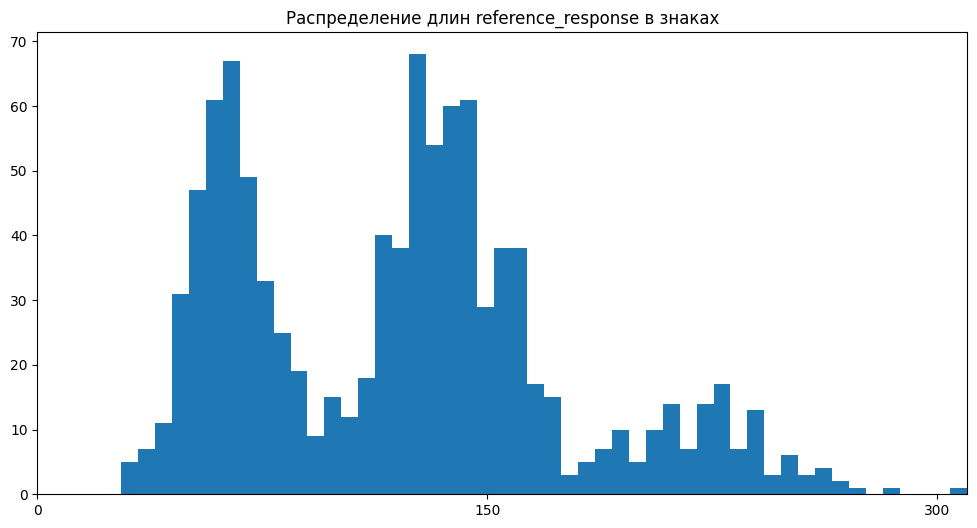

In [12]:
plt.figure(figsize=PLT_FIGSIZE)
plt.title("Распределение длин reference_response в знаках")
plt.xlim(right=max_chars_len)
plt.hist(llm_chars_len, bins=50)
plt.xticks(range(0, max(llm_chars_len), 150))
plt.show()

## Zero-shot режим

### Decoder-only

In [13]:
decoder_tokenizer = AutoTokenizer.from_pretrained(DECODER_ONLY_MODEL)
decoder_model = AutoModelForCausalLM.from_pretrained(
    DECODER_ONLY_MODEL,
    torch_dtype=torch.float32,
    device_map="auto",
)
decoder_model.generation_config.pad_token_id = decoder_model.generation_config.eos_token_id
decoder_model.eval()

GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 768)
    (wpe): Embedding(1024, 768)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-5): 6 x GPT2Block(
        (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D()
          (c_proj): Conv1D()
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D()
          (c_proj): Conv1D()
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
  )
  (lm_head): Linear(in_features=768, out_features=50257, bias=False)
)

In [14]:
def decoder_generate(prompt):
    inputs = decoder_tokenizer(prompt, return_tensors="pt").to(device)

    with torch.inference_mode():
        outputs = decoder_model.generate(
            **inputs,
            max_new_tokens=80,
            repetition_penalty=1.2,
        )

    generated = outputs[0, inputs["input_ids"].shape[-1]:].to("cpu")

    return decoder_tokenizer.decode(
        generated,
        skip_special_tokens=True,
    ).strip()

In [15]:
decoder_model_responses = [
    decoder_generate(prompt)
    for prompt in tqdm(df_test["human_prompt"].to_list())
]

  0%|          | 0/200 [00:00<?, ?it/s]

100%|██████████| 200/200 [01:44<00:00,  1.91it/s]


In [16]:
df_test["decoder_pre_finetune"] = decoder_model_responses
df_test.to_csv(CSV_TEST_PATH, index=False)
df_test[["human_prompt", "reference_response", "decoder_pre_finetune"]].head()

,human_prompt,reference_response,decoder_pre_finetune
521,I am new to Fiber. What are the two most impor...,"First, dietary fiber is plant material that is...",1) You can use your own fiber network and you ...
737,Explain Project management in simple terms.,"Project management organizes scope, time, reso...",The project manager is a very good example of ...
740,I need some help: write a two-sentence story a...,"The cat spoke only once a year, always on the ...",The first thing you should do is to read the e...
660,"Give a short explanation of Melody, including ...",A melody is a recognizable sequence of musical...,The following is the list of all possible ways...
411,I am new to Baking. What are the two most impo...,"First, baking cooks food mainly through dry he...","1) You can't make a recipe for your own cake, ..."


In [17]:
decoder_metrics_before = calculate_metrics(
    df_test["reference_response"].to_list(),
    decoder_model_responses,
)
decoder_metrics_before

{'BLEU': 1.4800106282432516e-79, 'METEOR': 0.11546238018482936}

In [18]:
del decoder_model
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

### Encoder-decoder

In [19]:
encoder_decoder_tokenizer = AutoTokenizer.from_pretrained(ENCODER_DECODER_MODEL)
encoder_decoder_model = AutoModelForSeq2SeqLM.from_pretrained(
    ENCODER_DECODER_MODEL,
    torch_dtype=torch.float32,
    device_map="auto",
)
encoder_decoder_model.eval()

T5ForConditionalGeneration(
  (shared): Embedding(32128, 512)
  (encoder): T5Stack(
    (embed_tokens): Embedding(32128, 512)
    (block): ModuleList(
      (0): T5Block(
        (layer): ModuleList(
          (0): T5LayerSelfAttention(
            (SelfAttention): T5Attention(
              (q): Linear(in_features=512, out_features=384, bias=False)
              (k): Linear(in_features=512, out_features=384, bias=False)
              (v): Linear(in_features=512, out_features=384, bias=False)
              (o): Linear(in_features=384, out_features=512, bias=False)
              (relative_attention_bias): Embedding(32, 6)
            )
            (layer_norm): T5LayerNorm()
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (1): T5LayerFF(
            (DenseReluDense): T5DenseGatedActDense(
              (wi_0): Linear(in_features=512, out_features=1024, bias=False)
              (wi_1): Linear(in_features=512, out_features=1024, bias=False)
              (wo): 

In [20]:
def encoder_decoder_generate(prompt):
    inputs = encoder_decoder_tokenizer(
        prompt,
        return_tensors="pt",
    ).to(device)

    with torch.inference_mode():
        output_ids = encoder_decoder_model.generate(
            **inputs,
            max_new_tokens=80,
            repetition_penalty=1.2,
        )

    return encoder_decoder_tokenizer.decode(
        output_ids[0],
        skip_special_tokens=True,
    ).strip()

In [21]:
encoder_decoder_model_responses = [
    encoder_decoder_generate(prompt)
    for prompt in tqdm(df_test["human_prompt"].to_list())
]

100%|██████████| 200/200 [00:52<00:00,  3.78it/s]


In [22]:
df_test["encoder_decoder_pre_finetune"] = encoder_decoder_model_responses
df_test.to_csv(CSV_TEST_PATH, index=False)
df_test[["human_prompt", "reference_response", "encoder_decoder_pre_finetune"]].head()

,human_prompt,reference_response,encoder_decoder_pre_finetune
521,I am new to Fiber. What are the two most impor...,"First, dietary fiber is plant material that is...",I am a student at the University of California...
737,Explain Project management in simple terms.,"Project management organizes scope, time, reso...",Explain project management in simple terms.
740,I need some help: write a two-sentence story a...,"The cat spoke only once a year, always on the ...",The cat is a very cute cat. He is a very cute ...
660,"Give a short explanation of Melody, including ...",A melody is a recognizable sequence of musical...,Melody is a song by the American rock band The...
411,I am new to Baking. What are the two most impo...,"First, baking cooks food mainly through dry he...",I am a baker.


In [23]:
encoder_decoder_metrics_before = calculate_metrics(
    df_test["reference_response"].to_list(),
    encoder_decoder_model_responses,
)
encoder_decoder_metrics_before

{'BLEU': 0.011659067322198007, 'METEOR': 0.08932185542629054}

In [24]:
del encoder_decoder_model
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

## Дообучение моделей

### Decoder-only

#### Finetuning

In [25]:
decoder_tokenizer = AutoTokenizer.from_pretrained(DECODER_ONLY_MODEL)
decoder_tokenizer.pad_token = decoder_tokenizer.eos_token

decoder_model = AutoModelForCausalLM.from_pretrained(
    DECODER_ONLY_MODEL,
    torch_dtype=torch.float32,
    device_map="auto",
)
decoder_model.config.pad_token_id = decoder_tokenizer.pad_token_id

decoder_data_collator = DataCollatorForSeq2Seq(
    tokenizer=decoder_tokenizer,
    model=decoder_model,
)

In [26]:
def tokenize_for_decoder_finetuning(prompt, reference_answer, tokenizer):
    prompt = f"User: {prompt}\nAssistant:"
    answer = f" {reference_answer}"

    prompt_ids = tokenizer(
        prompt,
        add_special_tokens=False,
    )["input_ids"]
    answer_ids = tokenizer(
        answer,
        add_special_tokens=False,
    )["input_ids"]

    input_ids = prompt_ids + answer_ids + [tokenizer.eos_token_id]
    labels = [-100] * len(prompt_ids) + answer_ids + [tokenizer.eos_token_id]

    input_ids = input_ids[:tokenizer.model_max_length]
    labels = labels[:tokenizer.model_max_length]

    return {
        "input_ids": input_ids,
        "attention_mask": [1] * len(input_ids),
        "labels": labels,
    }

In [27]:
decoder_finetuning_dataset = [
    tokenize_for_decoder_finetuning(prompt, reference, decoder_tokenizer)
    for prompt, reference in zip(
        df_train["human_prompt"],
        df_train["reference_response"],
    )
]

In [28]:
train_size = int(len(decoder_finetuning_dataset) * 0.8)
val_size = len(decoder_finetuning_dataset) - train_size

decoder_train_set, decoder_val_set = torch.utils.data.random_split(
    decoder_finetuning_dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(RANDOM_SEED),
)

In [29]:
decoder_training_args = TrainingArguments(
    output_dir="decoder_finetuned",
    num_train_epochs=1,
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    save_strategy="no",
    report_to="none",
    seed=RANDOM_SEED,
)

decoder_trainer = Trainer(
    model=decoder_model,
    args=decoder_training_args,
    train_dataset=decoder_train_set,
    eval_dataset=decoder_val_set,
    data_collator=decoder_data_collator,
    tokenizer=decoder_tokenizer,
)

decoder_trainer.train()
decoder_trainer.save_model("decoder_finetuned/final")

Step,Training Loss


#### Тест

In [30]:
decoder_checkpoint = "decoder_finetuned/final"

finetuned_decoder_tokenizer = AutoTokenizer.from_pretrained(decoder_checkpoint)
finetuned_decoder_model = AutoModelForCausalLM.from_pretrained(
    decoder_checkpoint,
    torch_dtype=torch.float32,
    device_map="auto",
)
finetuned_decoder_model.generation_config.pad_token_id = (
    finetuned_decoder_model.generation_config.eos_token_id
)
finetuned_decoder_model.eval()

GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 768)
    (wpe): Embedding(1024, 768)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-5): 6 x GPT2Block(
        (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D()
          (c_proj): Conv1D()
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D()
          (c_proj): Conv1D()
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
  )
  (lm_head): Linear(in_features=768, out_features=50257, bias=False)
)

In [31]:
def finetuned_decoder_generate(prompt):
    formatted_prompt = f"User: {prompt}\nAssistant:"
    inputs = finetuned_decoder_tokenizer(
        formatted_prompt,
        return_tensors="pt",
    ).to(device)

    with torch.inference_mode():
        outputs = finetuned_decoder_model.generate(
            **inputs,
            max_new_tokens=80,
            repetition_penalty=1.2,
        )

    generated = outputs[0, inputs["input_ids"].shape[-1]:].to("cpu")

    return finetuned_decoder_tokenizer.decode(
        generated,
        skip_special_tokens=True,
    ).strip()

In [32]:
finetuned_decoder_model_responses = [
    finetuned_decoder_generate(prompt)
    for prompt in tqdm(df_test["human_prompt"].to_list())
]

100%|██████████| 200/200 [00:41<00:00,  4.78it/s]


In [33]:
df_test["decoder_post_finetune"] = finetuned_decoder_model_responses
df_test.to_csv(CSV_TEST_PATH, index=False)
df_test[["human_prompt", "reference_response", "decoder_post_finetune"]].head()

,human_prompt,reference_response,decoder_post_finetune
521,I am new to Fiber. What are the two most impor...,"First, dietary fiber is plant material that is...","First, fiber is a network of interconnected ne..."
737,Explain Project management in simple terms.,"Project management organizes scope, time, reso...",A project manager is a person who works with p...
740,I need some help: write a two-sentence story a...,"The cat spoke only once a year, always on the ...",A kitten is an orphaned puppy who has been aba...
660,"Give a short explanation of Melody, including ...",A melody is a recognizable sequence of musical...,A melody is the same as any other song or vide...
411,I am new to Baking. What are the two most impo...,"First, baking cooks food mainly through dry he...","First, baking is a process that involves mixin..."


In [34]:
decoder_metrics_after = calculate_metrics(
    df_test["reference_response"].to_list(),
    finetuned_decoder_model_responses,
)
decoder_metrics_after

{'BLEU': 5.466813319925178e-79, 'METEOR': 0.13273361388048507}

In [35]:
del decoder_model, finetuned_decoder_model, decoder_trainer
del decoder_data_collator
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

### Encoder-decoder

#### Finetuning

In [36]:
encoder_decoder_tokenizer = AutoTokenizer.from_pretrained(ENCODER_DECODER_MODEL)
encoder_decoder_model = AutoModelForSeq2SeqLM.from_pretrained(
    ENCODER_DECODER_MODEL,
    torch_dtype=torch.float32,
    device_map="auto",
)

encoder_decoder_data_collator = DataCollatorForSeq2Seq(
    tokenizer=encoder_decoder_tokenizer,
    model=encoder_decoder_model,
)

In [37]:
def tokenize_for_encoder_decoder_finetuning(prompt, reference_answer, tokenizer):
    tokenized = tokenizer(
        prompt,
        max_length=256,
        truncation=True,
    )
    tokenized["labels"] = tokenizer(
        text_target=reference_answer,
        max_length=128,
        truncation=True,
    )["input_ids"]

    return tokenized

In [38]:
encoder_decoder_finetuning_dataset = [
    tokenize_for_encoder_decoder_finetuning(
        prompt,
        reference,
        encoder_decoder_tokenizer,
    )
    for prompt, reference in zip(
        df_train["human_prompt"],
        df_train["reference_response"],
    )
]

In [39]:
train_size = int(len(encoder_decoder_finetuning_dataset) * 0.8)
val_size = len(encoder_decoder_finetuning_dataset) - train_size

encoder_decoder_train_set, encoder_decoder_val_set = torch.utils.data.random_split(
    encoder_decoder_finetuning_dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(RANDOM_SEED),
)

In [40]:
encoder_decoder_training_args = TrainingArguments(
    output_dir="encoder_decoder_finetuned",
    num_train_epochs=1,
    learning_rate=2e-5,
    per_device_train_batch_size=2,
    per_device_eval_batch_size=2,
    gradient_accumulation_steps=4,
    gradient_checkpointing=True,
    optim="adafactor",
    save_strategy="no",
    report_to="none",
    seed=RANDOM_SEED,
)

encoder_decoder_trainer = Trainer(
    model=encoder_decoder_model,
    args=encoder_decoder_training_args,
    train_dataset=encoder_decoder_train_set,
    eval_dataset=encoder_decoder_val_set,
    data_collator=encoder_decoder_data_collator,
    tokenizer=encoder_decoder_tokenizer,
)

encoder_decoder_trainer.train()
encoder_decoder_trainer.save_model("encoder_decoder_finetuned/final")

`use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`...


Step,Training Loss


#### Тест

In [41]:
encoder_decoder_checkpoint = "encoder_decoder_finetuned/final"

finetuned_encoder_decoder_tokenizer = AutoTokenizer.from_pretrained(
    encoder_decoder_checkpoint
)
finetuned_encoder_decoder_model = AutoModelForSeq2SeqLM.from_pretrained(
    encoder_decoder_checkpoint,
    torch_dtype=torch.float32,
    device_map="auto",
)
finetuned_encoder_decoder_model.eval()

T5ForConditionalGeneration(
  (shared): Embedding(32128, 512)
  (encoder): T5Stack(
    (embed_tokens): Embedding(32128, 512)
    (block): ModuleList(
      (0): T5Block(
        (layer): ModuleList(
          (0): T5LayerSelfAttention(
            (SelfAttention): T5Attention(
              (q): Linear(in_features=512, out_features=384, bias=False)
              (k): Linear(in_features=512, out_features=384, bias=False)
              (v): Linear(in_features=512, out_features=384, bias=False)
              (o): Linear(in_features=384, out_features=512, bias=False)
              (relative_attention_bias): Embedding(32, 6)
            )
            (layer_norm): T5LayerNorm()
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (1): T5LayerFF(
            (DenseReluDense): T5DenseGatedActDense(
              (wi_0): Linear(in_features=512, out_features=1024, bias=False)
              (wi_1): Linear(in_features=512, out_features=1024, bias=False)
              (wo): 

In [42]:
def finetuned_encoder_decoder_generate(prompt):
    inputs = finetuned_encoder_decoder_tokenizer(
        prompt,
        return_tensors="pt",
    ).to(device)

    with torch.inference_mode():
        output_ids = finetuned_encoder_decoder_model.generate(
            **inputs,
            max_new_tokens=80,
            repetition_penalty=1.2,
        )

    return finetuned_encoder_decoder_tokenizer.decode(
        output_ids[0],
        skip_special_tokens=True,
    ).strip()

In [43]:
finetuned_encoder_decoder_model_responses = [
    finetuned_encoder_decoder_generate(prompt)
    for prompt in tqdm(df_test["human_prompt"].to_list())
]

100%|██████████| 200/200 [00:48<00:00,  4.10it/s]


In [44]:
df_test["encoder_decoder_post_finetune"] = (
    finetuned_encoder_decoder_model_responses
)
df_test.to_csv(CSV_TEST_PATH, index=False)
df_test[
    ["human_prompt", "reference_response", "encoder_decoder_post_finetune"]
].head()

,human_prompt,reference_response,encoder_decoder_post_finetune
521,I am new to Fiber. What are the two most impor...,"First, dietary fiber is plant material that is...",Fiber is a fiber that connects to the fibers o...
737,Explain Project management in simple terms.,"Project management organizes scope, time, reso...",Project management is the process of establish...
740,I need some help: write a two-sentence story a...,"The cat spoke only once a year, always on the ...",The cat is a very cute cat. He is a very frien...
660,"Give a short explanation of Melody, including ...",A melody is a recognizable sequence of musical...,Melody is a song that is a musical composition...
411,I am new to Baking. What are the two most impo...,"First, baking cooks food mainly through dry he...",Baking is a process that requires a lot of tim...


In [45]:
encoder_decoder_metrics_after = calculate_metrics(
    df_test["reference_response"].to_list(),
    finetuned_encoder_decoder_model_responses,
)
encoder_decoder_metrics_after

{'BLEU': 0.022823373380641852, 'METEOR': 0.10958602474747621}

## Сравнение zero-shot и дообученной модели

### Decoder-only

In [46]:
decoder_comparison = pd.DataFrame(
    [decoder_metrics_before, decoder_metrics_after],
    index=["zero-shot", "finetuned"],
)
decoder_comparison.loc["difference"] = (
    decoder_comparison.loc["finetuned"]
    - decoder_comparison.loc["zero-shot"]
)
decoder_comparison

,BLEU,METEOR
zero-shot,1.480011e-79,0.115462
finetuned,5.466813e-79,0.132734
difference,3.986803e-79,0.017271


### Encoder-decoder

In [47]:
encoder_decoder_comparison = pd.DataFrame(
    [encoder_decoder_metrics_before, encoder_decoder_metrics_after],
    index=["zero-shot", "finetuned"],
)
encoder_decoder_comparison.loc["difference"] = (
    encoder_decoder_comparison.loc["finetuned"]
    - encoder_decoder_comparison.loc["zero-shot"]
)
encoder_decoder_comparison

,BLEU,METEOR
zero-shot,0.011659,0.089322
finetuned,0.022823,0.109586
difference,0.011164,0.020264
